# HW2（資料集 B）：人機互動信任分數之多元線性回歸分析（CRISP-DM）

- **資料集**：Human-AI Interaction（Kaggle, eshaalnmalik）
  <https://www.kaggle.com/datasets/eshaalnmalik/human-ai-interaction>
- **筆數 / 欄位**：10,100 筆、21 欄（20 個特徵 + 1 個目標）
- **目標變數**：`latent_trust_score`（使用者對 AI 系統的信任分數，約 38–100）
- **方法**：簡單線性回歸（基準）→ 多元線性回歸 → 特徵選擇（Forward Stepwise-AIC、RFE、LassoCV）→ 評估 → 預測區間 → 部署（GitHub Pages）

> 🤖 **GPT 輔助內容**：本 notebook 之程式架構、特徵工程與文字說明由 AI 助理（Claude）協助產生，經作者檢閱與執行。

In [1]:
import warnings, json, os
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression, LassoCV
from sklearn.feature_selection import RFE
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

RNG = 42
FIG = "docs/trust/assets"; os.makedirs(FIG, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 140, "savefig.bbox": "tight"})
ACC, ACC2, GREY = "#2563eb", "#f97316", "#64748b"
def save(name): plt.savefig(f"{FIG}/{name}.png"); plt.show()

## 1. Business Understanding（商業理解）

**問題**：AI 系統（推薦、醫療輔助、金融決策、自駕等）能否被採用，關鍵在於使用者是否**信任**它。過度不信任會讓好的模型沒人用，過度信任則可能造成錯誤決策。

**目標**：以使用者特徵（年齡、教育、技術經驗、認知負荷）、AI 系統特性（準確率、可解釋性、偏誤、錯誤率、介面複雜度）與情境（領域、風險、時間壓力、法規）預測 `latent_trust_score`，並找出**真正影響信任的因素**。

**成功標準**
- 測試集 R² ≥ 0.65
- 特徵選擇後模型更精簡且表現不下降
- 95% 預測區間覆蓋率接近 95%

**應用**：產品團隊可以知道「提升準確率 10 個百分點」或「把介面從高複雜度降到低複雜度」能換到多少信任分數。

## 2. Data Understanding（資料理解）

In [2]:
raw = pd.read_csv("data/human_ai_interaction.csv")
print(raw.shape)
raw.head()

(10100, 21)


,age,education_level,technical_experience,cognitive_load,prior_ai_exposure,model_accuracy,explainability_score,bias_level,decision_latency,error_rate,...,ui_complexity,feedback_quality,trust_history,override_frequency,task_risk,domain,time_pressure,cultural_factor,regulatory_strictness,latent_trust_score
0,23.0,Bachelor,10.0,0.165784,Low,0.751659,0.849591,0.997805,0.177149,0.240530,...,Medium,0.153828,0.098937,14.0,Medium,E-commerce,0.296228,Asian,1.0,53.997197
1,57.0,Bachelor,5.0,0.795383,High,0.942052,0.678777,0.608413,3.232353,0.069060,...,Medium,0.703003,0.945327,14.0,Low,Education,0.958935,Western,5.0,75.390600
2,22.0,Bachelor,1.0,0.985904,Medium,0.626350,0.741697,0.238885,4.591147,0.371519,...,Medium,0.949976,0.679748,15.0,Medium,Transportation,0.545855,African,3.0,76.728664
3,18.0,High School,9.0,0.643739,Low,0.517244,0.868427,0.866096,3.969884,0.486810,...,Medium,0.249026,0.293486,3.0,Low,Finance,0.897044,African,5.0,57.634055
4,32.0,Bachelor,9.0,0.639220,Medium,0.889796,0.627548,0.602626,3.695765,0.115761,...,Low,0.090495,0.148895,0.0,Low,E-commerce,0.353964,Asian,4.0,73.563222


In [3]:
info = pd.DataFrame({"dtype": raw.dtypes.astype(str),
                     "missing": raw.isna().sum(),
                     "missing_%": (raw.isna().mean()*100).round(2),
                     "n_unique": raw.nunique()})
print("duplicated rows:", raw.duplicated().sum(), "| rows with any missing:", raw.isna().any(axis=1).sum())
info

duplicated rows: 100 | rows with any missing: 3493


,dtype,missing,missing_%,n_unique
age,float64,203,2.01,47
education_level,object,203,2.01,4
technical_experience,float64,201,1.99,21
cognitive_load,float64,203,2.01,9800
prior_ai_exposure,object,201,1.99,3
model_accuracy,float64,203,2.01,9800
explainability_score,float64,202,2.00,9800
bias_level,float64,201,1.99,9800
decision_latency,float64,202,2.00,9800
error_rate,float64,203,2.01,9800


In [4]:
raw.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
age,9897.0,41.099,13.468,18.000,30.000,41.000,53.000,64.000
technical_experience,9899.0,10.048,6.039,0.000,5.000,10.000,15.000,20.000
cognitive_load,9897.0,0.495,0.286,0.000,0.246,0.496,0.737,1.000
model_accuracy,9897.0,0.749,0.144,0.500,0.624,0.751,0.874,1.000
explainability_score,9898.0,0.501,0.288,0.000,0.256,0.498,0.753,1.000
bias_level,9899.0,0.502,0.287,0.000,0.253,0.503,0.753,1.000
decision_latency,9898.0,2.565,1.411,0.101,1.331,2.596,3.786,4.999
error_rate,9897.0,0.250,0.146,-0.050,0.127,0.250,0.376,0.545
interaction_frequency,9898.0,24.997,14.115,1.000,13.000,25.000,37.000,49.000
feedback_quality,9900.0,0.499,0.289,0.000,0.246,0.498,0.751,1.000


**觀察**
1. 每個欄位都有約 2% 的隨機缺值，若直接刪除含缺值的列會損失約 35% 的資料 → 改用**填補**。
2. 有 100 筆完全重複的列 → 刪除。
3. `error_rate` 出現負值（最小 −0.05），不合理 → 截斷為 0。
4. 目標 `latent_trust_score` 接近常態（平均 70.5、標準差 9.1），上限為 100 → 不需要取 log。

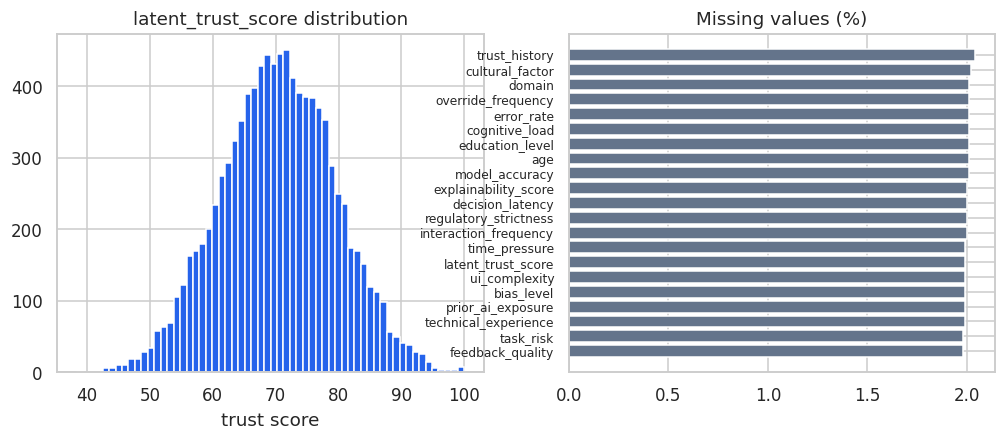

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(raw.latent_trust_score.dropna(), bins=60, color=ACC); axes[0].set_title("latent_trust_score distribution"); axes[0].set_xlabel("trust score")
m = raw.isna().mean().sort_values()*100
axes[1].barh(m.index, m.values, color=GREY); axes[1].set_title("Missing values (%)"); axes[1].tick_params(axis="y", labelsize=8)
save("01_target_missing")

## 3. Data Preparation（資料準備）

| 步驟 | 做法 | 理由 |
|---|---|---|
| 重複值 | 刪除 100 筆完全重複的列 | 避免同一筆資料同時出現在訓練與測試集 |
| 目標缺值 | 刪除 `latent_trust_score` 缺值的列 | 無法訓練也無法評估 |
| 不合理值 | `error_rate` 截斷到 ≥ 0 | 錯誤率不可能為負 |
| 切分 | 先切 80/20 訓練/測試，**再**填補 | 填補值只從訓練集計算，避免資料洩漏 |
| 缺值填補 | 數值用訓練集中位數、類別用訓練集眾數 | 缺值隨機且比例低 |
| 編碼 | 類別 one-hot（drop_first） | 線性模型需要數值輸入 |

In [6]:
df = raw.drop_duplicates().dropna(subset=["latent_trust_score"]).copy()
df["error_rate"] = df["error_rate"].clip(lower=0)
TARGET = "latent_trust_score"
CAT = ["education_level","prior_ai_exposure","ui_complexity","task_risk","domain","cultural_factor"]
NUM = [c for c in df.columns if c not in CAT + [TARGET]]
print(f"rows after cleaning: {len(df)} | {len(NUM)} numeric + {len(CAT)} categorical = {len(NUM)+len(CAT)} features")

tr, te = train_test_split(df, test_size=0.2, random_state=RNG)
fill = {c: tr[c].median() for c in NUM} | {c: tr[c].mode()[0] for c in CAT}
tr, te = tr.fillna(fill), te.fillna(fill)
LEVELS = {c: sorted(df[c].dropna().unique().tolist()) for c in CAT}

def encode(d):
    X = d[NUM].copy()
    for c in CAT:
        for lv in LEVELS[c][1:]:               # drop_first: the first (alphabetical) level is the baseline
            X[f"{c}_{lv}"] = (d[c] == lv).astype(float)
    return X
X_tr, X_te = encode(tr), encode(te)
y_tr, y_te = tr[TARGET].values, te[TARGET].values
X_all, y_all = pd.concat([X_tr, X_te]), np.concatenate([y_tr, y_te])
GROUPS = {c: [c] for c in NUM} | {c: [k for k in X_tr.columns if k.startswith(c + "_")] for c in CAT}
print("train", X_tr.shape, " test", X_te.shape)

rows after cleaning: 9800 | 14 numeric + 6 categorical = 20 features
train (7840, 30)  test (1960, 30)


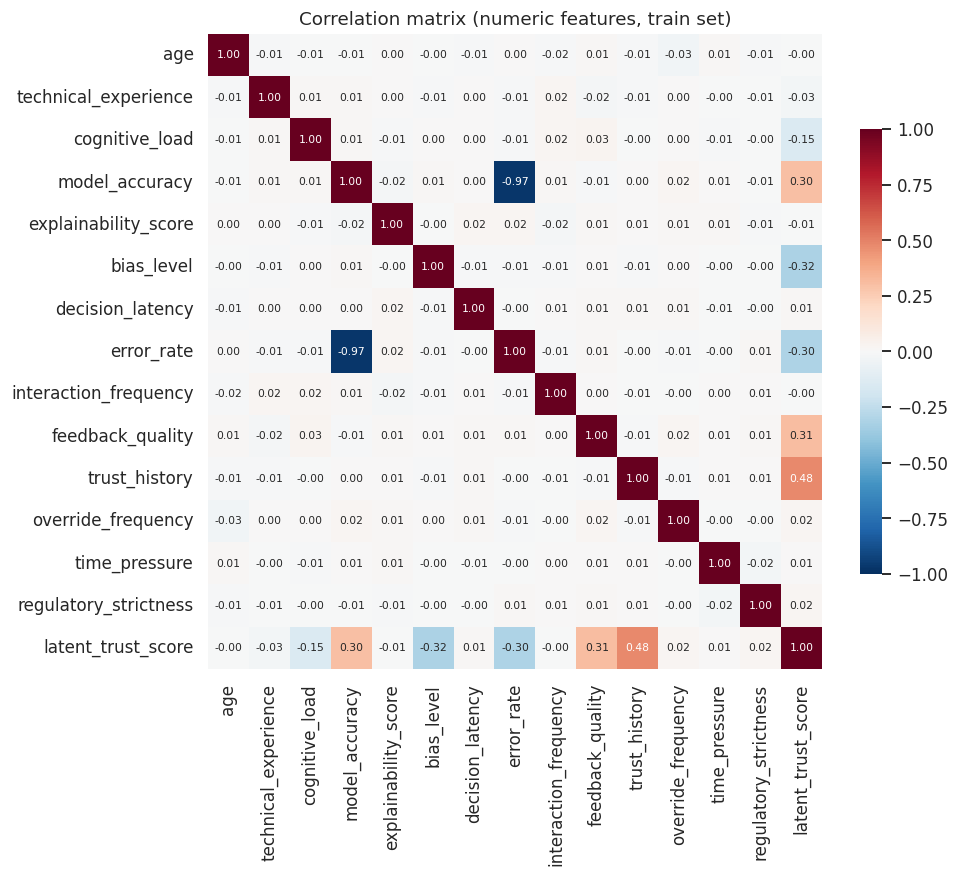

In [7]:
fig, ax = plt.subplots(figsize=(9, 7.5))
corr = tr[NUM + [TARGET]].corr()
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax, cbar_kws={"shrink": .7})
ax.set_title("Correlation matrix (numeric features, train set)")
save("02_corr")

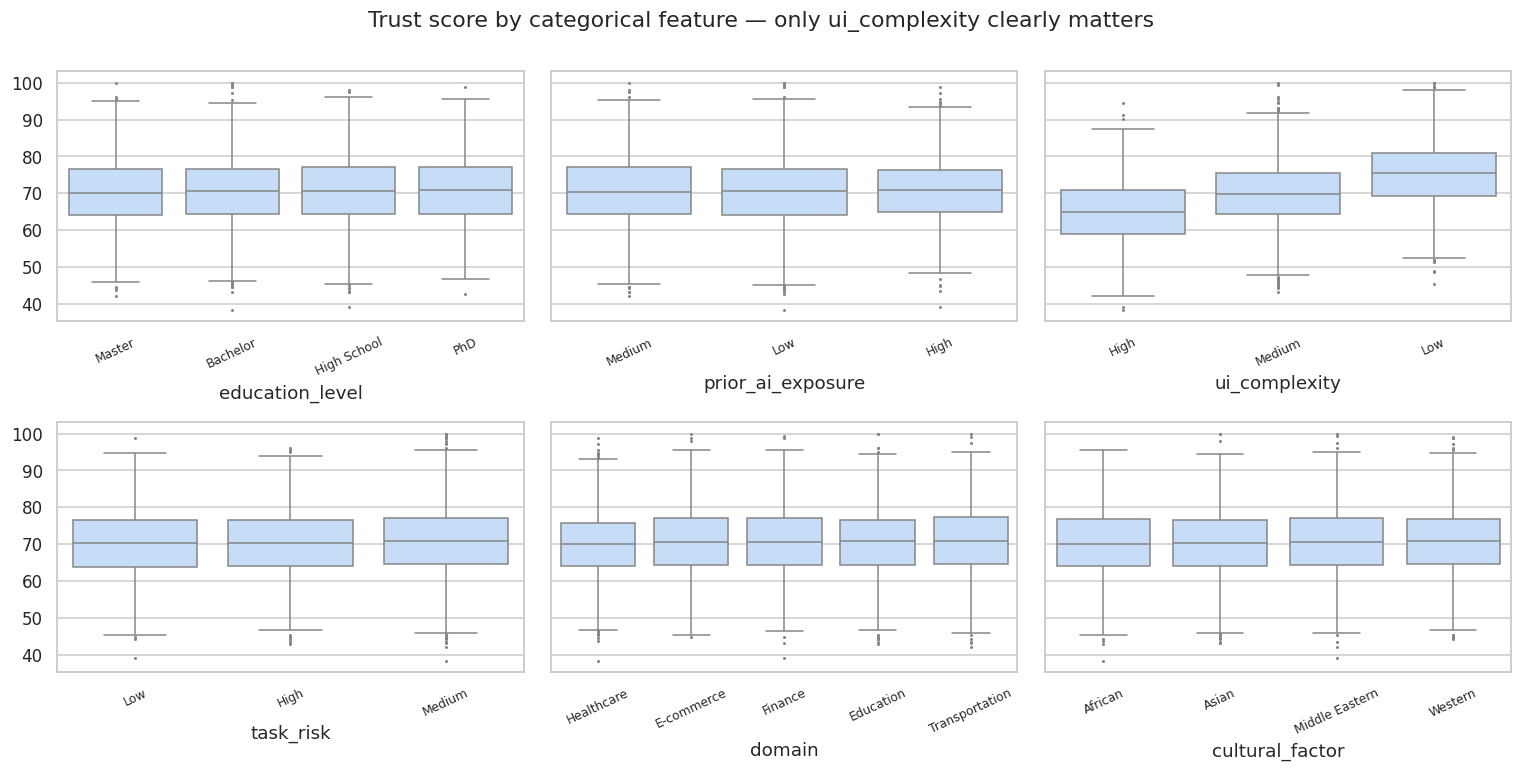

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=True)
for ax, c in zip(axes.ravel(), CAT):
    order = tr.groupby(c)[TARGET].median().sort_values().index
    sns.boxplot(data=tr, x=c, y=TARGET, order=order, color="#bfdbfe", fliersize=1, ax=ax)
    ax.set_xlabel(c); ax.tick_params(axis="x", rotation=25, labelsize=8); ax.set_ylabel("")
fig.suptitle("Trust score by categorical feature — only ui_complexity clearly matters", y=1.0)
plt.tight_layout(); save("03_cat_box")

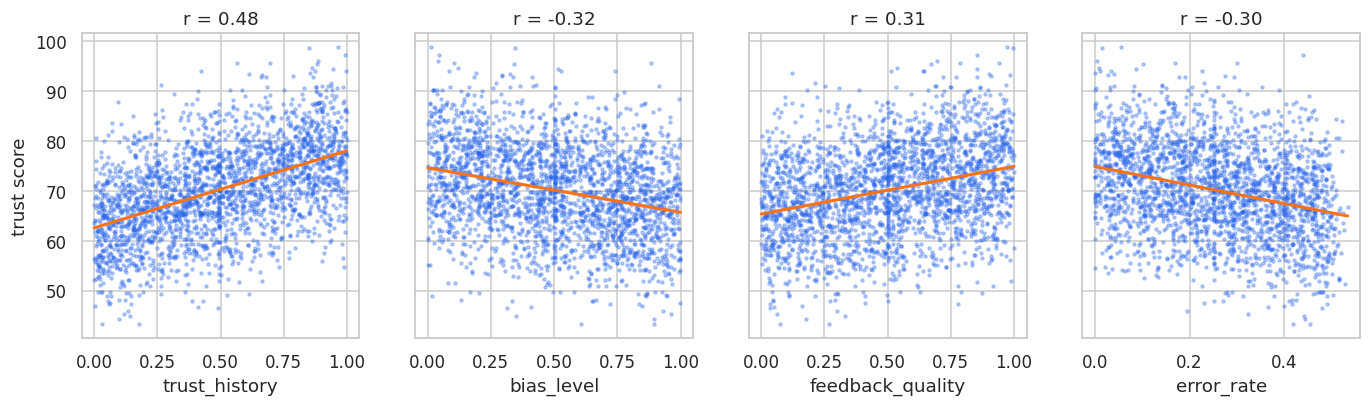

In [9]:
top4 = corr[TARGET].drop(TARGET).abs().sort_values(ascending=False).index[:4]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
smp = tr.sample(2500, random_state=RNG)
for ax, c in zip(axes, top4):
    ax.scatter(smp[c], smp[TARGET], s=4, alpha=.3, color=ACC)
    b = np.polyfit(smp[c], smp[TARGET], 1); xs = np.linspace(smp[c].min(), smp[c].max(), 50)
    ax.plot(xs, np.polyval(b, xs), color=ACC2, lw=2); ax.set_xlabel(c); ax.set_title(f"r = {corr.loc[c, TARGET]:.2f}")
axes[0].set_ylabel("trust score")
save("04_scatter_top")

## 4. Modeling（建模）

### 4.1 基準模型：簡單線性回歸（與目標相關最高的單一特徵）

In [10]:
def metrics(y, yhat, p):
    n = len(y); r2 = r2_score(y, yhat)
    return {"R2": r2, "adjR2": 1-(1-r2)*(n-1)/(n-p-1),
            "RMSE": np.sqrt(mean_squared_error(y, yhat)), "MAE": mean_absolute_error(y, yhat),
            "MAPE_%": 100*np.mean(np.abs(yhat-y)/y)}
def fit_ols(cols): return sm.OLS(y_tr, sm.add_constant(X_tr[cols])).fit()

best1 = top4[0]
results = {}
slr = fit_ols([best1])
results[f"SLR ({best1})"] = metrics(y_te, slr.predict(sm.add_constant(X_te[[best1]])), 1)
print(slr.summary().tables[1])

                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const            62.8474      0.182    345.211      0.000      62.491      63.204
trust_history    15.3267      0.317     48.297      0.000      14.705      15.949


### 4.2 全特徵多元線性回歸（Full MLR）

In [11]:
full_cols = list(X_tr.columns)
full = fit_ols(full_cols)
results["MLR full"] = metrics(y_te, full.predict(sm.add_constant(X_te[full_cols])), len(full_cols))
print(f"features: {len(full_cols)}  train adjR2={full.rsquared_adj:.4f}  AIC={full.aic:.0f}")
full.summary().tables[1]

features: 30  train adjR2=0.6911  AIC=47772


,coef,std err,t,P>|t|,[0.025,0.975]
const,54.3406,1.677,32.398,0.000,51.053,57.629
age,-0.0002,0.004,-0.047,0.963,-0.009,0.008
technical_experience,-0.0159,0.010,-1.655,0.098,-0.035,0.003
cognitive_load,-5.0905,0.203,-25.064,0.000,-5.489,-4.692
model_accuracy,10.5914,1.624,6.523,0.000,7.408,13.774
explainability_score,-0.1599,0.202,-0.791,0.429,-0.556,0.236
bias_level,-10.1252,0.203,-49.768,0.000,-10.524,-9.726
decision_latency,-0.0153,0.041,-0.373,0.709,-0.096,0.065
error_rate,-9.6515,1.612,-5.989,0.000,-12.811,-6.492
interaction_frequency,-0.0062,0.004,-1.509,0.131,-0.014,0.002


### 4.3 特徵選擇 (Feature Selection)
1. **Forward Stepwise（AIC，特徵群組層級）**：每次加入使 AIC 下降最多的特徵群組，ΔAIC < 2 即停止。
2. **RFE**：標準化後以線性回歸遞迴刪除，保留 10 個欄位。
3. **LassoCV**：L1 正則化，5-fold CV 選 α。

In [12]:
def group_cols(gs): return [c for g in gs for c in GROUPS[g]]
selected, remaining, history = [], list(GROUPS), []
best_aic = sm.OLS(y_tr, np.ones(len(y_tr))).fit().aic
while remaining:
    aic, g = min((fit_ols(group_cols(selected + [g])).aic, g) for g in remaining)
    if aic >= best_aic - 2: break
    best_aic = aic; selected.append(g); remaining.remove(g)
    m = fit_ols(group_cols(selected))
    history.append({"step": len(selected), "added": g, "AIC": aic, "adjR2": m.rsquared_adj, "n_cols": len(group_cols(selected))})
hist = pd.DataFrame(history)
print("dropped groups:", remaining)
hist

dropped groups: ['age', 'technical_experience', 'explainability_score', 'decision_latency', 'interaction_frequency', 'time_pressure', 'education_level', 'prior_ai_exposure', 'task_risk', 'domain', 'cultural_factor']


,step,added,AIC,adjR2,n_cols
0,1,trust_history,54911.518693,0.229249,1
1,2,ui_complexity,53227.699082,0.378375,3
2,3,bias_level,51931.767918,0.473152,4
3,4,feedback_quality,50377.124566,0.567973,5
4,5,model_accuracy,48400.088842,0.664310,6
5,6,cognitive_load,47798.389768,0.689149,7
6,7,error_rate,47764.669097,0.690523,8
7,8,override_frequency,47756.947329,0.690867,9
8,9,regulatory_strictness,47753.419063,0.691045,10


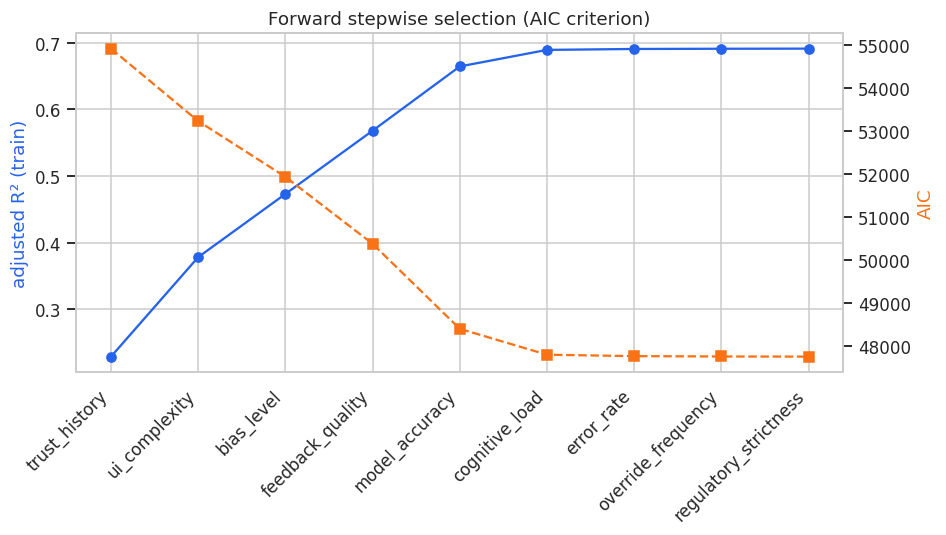

In [13]:
fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(hist.step, hist.adjR2, "o-", color=ACC); ax1.set_ylabel("adjusted R² (train)", color=ACC)
ax1.set_xticks(hist.step); ax1.set_xticklabels(hist.added, rotation=45, ha="right")
ax2 = ax1.twinx(); ax2.plot(hist.step, hist.AIC, "s--", color=ACC2); ax2.set_ylabel("AIC", color=ACC2); ax2.grid(False)
ax1.set_title("Forward stepwise selection (AIC criterion)")
save("05_stepwise")

In [14]:
sc = StandardScaler().fit(X_tr)
rfe = RFE(LinearRegression(), n_features_to_select=10).fit(sc.transform(X_tr), y_tr)
rfe_cols = list(X_tr.columns[rfe.support_])
lasso = LassoCV(cv=5, random_state=RNG, n_alphas=80).fit(sc.transform(X_tr), y_tr)
lasso_coef = pd.Series(lasso.coef_, index=X_tr.columns)
lasso_cols = list(lasso_coef[lasso_coef != 0].index)
print(f"RFE kept {len(rfe_cols)} | Lasso alpha={lasso.alpha_:.4f} kept {len(lasso_cols)}/{X_tr.shape[1]}")
cmp = pd.DataFrame({g: {"Stepwise-AIC": g in selected,
                        "RFE(10)": any(c in rfe_cols for c in GROUPS[g]),
                        "Lasso": any(c in lasso_cols for c in GROUPS[g])} for g in GROUPS}).T
cmp["votes"] = cmp.sum(axis=1)
cmp.sort_values("votes", ascending=False)

RFE kept 10 | Lasso alpha=0.0194 kept 25/30


,Stepwise-AIC,RFE(10),Lasso,votes
model_accuracy,True,True,True,3
cognitive_load,True,True,True,3
error_rate,True,True,True,3
bias_level,True,True,True,3
override_frequency,True,True,True,3
regulatory_strictness,True,True,True,3
trust_history,True,True,True,3
feedback_quality,True,True,True,3
ui_complexity,True,True,True,3
technical_experience,False,False,True,1


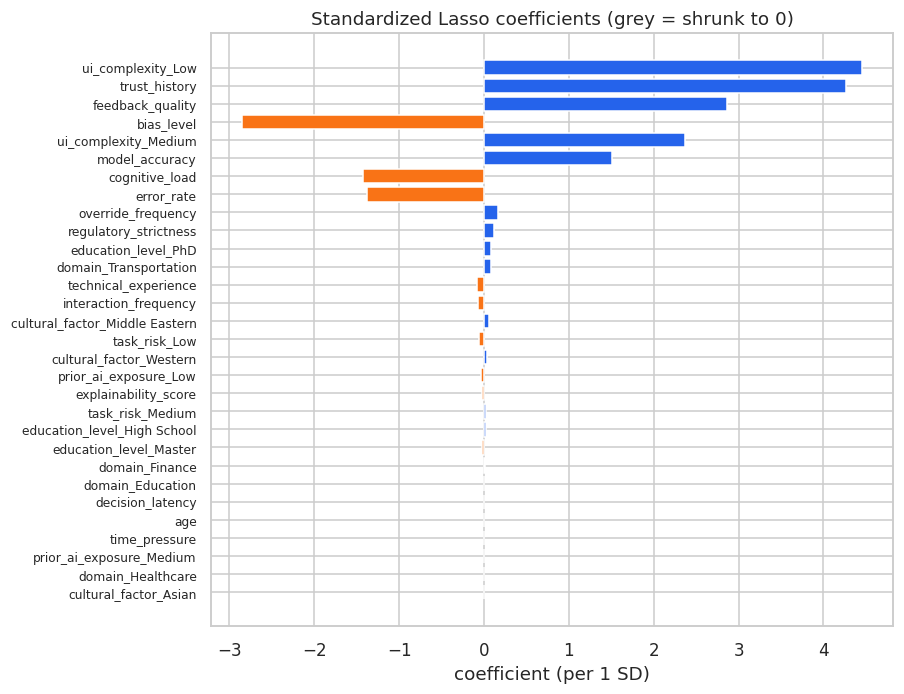

In [15]:
lc = lasso_coef.reindex(lasso_coef.abs().sort_values(ascending=False).index)
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(lc.index[::-1], lc.values[::-1], color=[ACC if v > 0 else (ACC2 if v < 0 else GREY) for v in lc.values[::-1]])
ax.set_title("Standardized Lasso coefficients (grey = shrunk to 0)"); ax.set_xlabel("coefficient (per 1 SD)"); ax.tick_params(axis="y", labelsize=8)
save("06_lasso_coef")

### 4.4 最終模型（Stepwise-AIC 選出之特徵）

In [16]:
sel_cols = group_cols(selected)
final = fit_ols(sel_cols)
results["MLR stepwise (final)"] = metrics(y_te, final.predict(sm.add_constant(X_te[sel_cols])), len(sel_cols))
results["MLR RFE(10)"] = metrics(y_te, fit_ols(rfe_cols).predict(sm.add_constant(X_te[rfe_cols])), len(rfe_cols))
results["Lasso (CV)"] = metrics(y_te, lasso.predict(sc.transform(X_te)), len(lasso_cols))
coef = pd.DataFrame({"coef": final.params, "p": final.pvalues, "CI_low": final.conf_int()[0], "CI_high": final.conf_int()[1]})
print(final.summary().tables[0])
coef.round(4)

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.691
Model:                            OLS   Adj. R-squared:                  0.691
Method:                 Least Squares   F-statistic:                     1754.
Date:                Tue, 27 Oct 2026   Prob (F-statistic):               0.00
Time:                        12:05:26   Log-Likelihood:                -23866.
No. Observations:                7840   AIC:                         4.775e+04
Df Residuals:                    7829   BIC:                         4.783e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         


,coef,p,CI_low,CI_high
const,54.1426,0.0000,50.9370,57.3481
trust_history,15.0190,0.0000,14.6249,15.4130
ui_complexity_Low,9.9284,0.0000,9.5990,10.2578
ui_complexity_Medium,4.8674,0.0000,4.5676,5.1672
bias_level,-10.1282,0.0000,-10.5260,-9.7304
feedback_quality,10.0561,0.0000,9.6633,10.4490
model_accuracy,10.5384,0.0000,7.3580,13.7188
cognitive_load,-5.0986,0.0000,-5.4962,-4.7009
error_rate,-9.6950,0.0000,-12.8515,-6.5385
override_frequency,0.0312,0.0018,0.0116,0.0508


**係數解讀**（目標未取 log，係數即「分數變化」）
- `model_accuracy`：準確率增加 0.1（10 個百分點），信任分數約增加 β×0.1 分。
- `ui_complexity_Low`／`_Medium`：相對於高複雜度介面（基準）的信任分數差。
- `bias_level`、`cognitive_load`：係數為負，偏誤越大、使用者認知負荷越高，信任越低。

## 5. Evaluation（評估）

In [17]:
res = pd.DataFrame(results).T
kf = KFold(5, shuffle=True, random_state=RNG)
res["CV5_R2"] = np.nan
for k, cols in {f"SLR ({best1})": [best1], "MLR full": full_cols, "MLR stepwise (final)": sel_cols, "MLR RFE(10)": rfe_cols}.items():
    res.loc[k, "CV5_R2"] = cross_val_score(LinearRegression(), X_all[cols], y_all, cv=kf, scoring="r2").mean()
res["n_features"] = [1, len(full_cols), len(sel_cols), len(rfe_cols), len(lasso_cols)]
res.round(4)

,R2,adjR2,RMSE,MAE,MAPE_%,CV5_R2,n_features
SLR (trust_history),0.2165,0.2161,7.9411,6.3428,9.2662,0.2266,1
MLR full,0.6944,0.6896,4.9595,3.9149,5.6614,0.6902,30
MLR stepwise (final),0.6947,0.6931,4.9573,3.9173,5.6637,0.6913,10
MLR RFE(10),0.6947,0.6931,4.9573,3.9173,5.6637,0.6913,10
Lasso (CV),0.6950,0.6911,4.9546,3.9120,5.6575,NaN,25


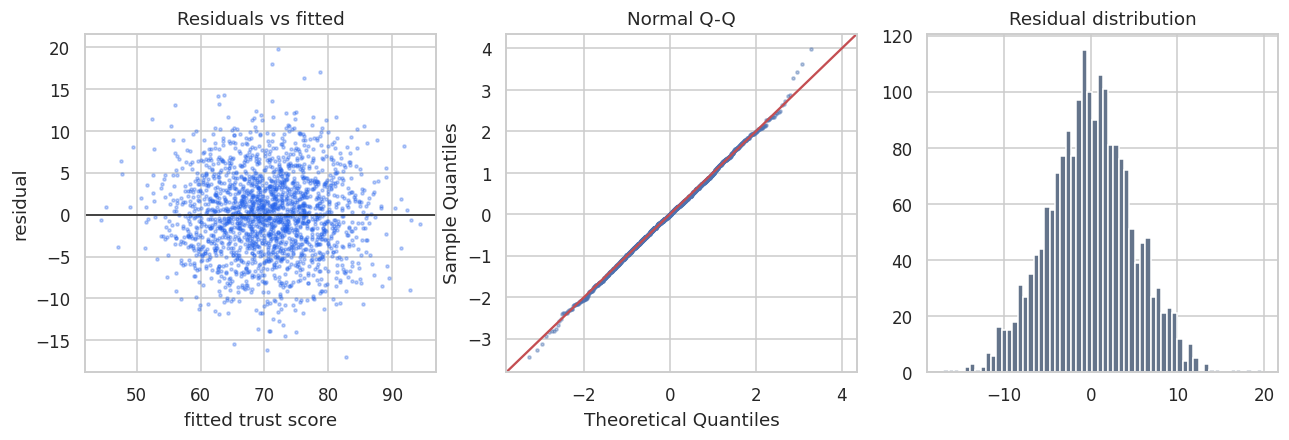

In [18]:
X_te_c = sm.add_constant(X_te[sel_cols])
yhat_te = final.predict(X_te_c); resid = y_te - yhat_te
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].scatter(yhat_te, resid, s=4, alpha=.3, color=ACC); axes[0].axhline(0, color="k", lw=1)
axes[0].set_xlabel("fitted trust score"); axes[0].set_ylabel("residual"); axes[0].set_title("Residuals vs fitted")
sm.qqplot(resid, line="45", fit=True, ax=axes[1], markersize=2, alpha=.4); axes[1].set_title("Normal Q-Q")
axes[2].hist(resid, bins=60, color=GREY); axes[2].set_title("Residual distribution")
save("07_residuals")

In [19]:
num_full = NUM
Xv = sm.add_constant(X_tr[num_full])
vif = pd.DataFrame({"feature": num_full, "VIF": [variance_inflation_factor(Xv.values, i+1) for i in range(len(num_full))]})
print("corr(model_accuracy, error_rate) =", round(tr.model_accuracy.corr(tr.error_rate), 3))
vif.sort_values("VIF", ascending=False).round(2)

corr(model_accuracy, error_rate) = -0.969


,feature,VIF
3,model_accuracy,16.3
7,error_rate,16.3
0,age,1.0
11,override_frequency,1.0
9,feedback_quality,1.0
8,interaction_frequency,1.0
2,cognitive_load,1.0
4,explainability_score,1.0
1,technical_experience,1.0
13,regulatory_strictness,1.0


### 5.1 預測圖（含信賴區間 CI 與預測區間 PI）

95% PI empirical coverage on test set: 95.4%


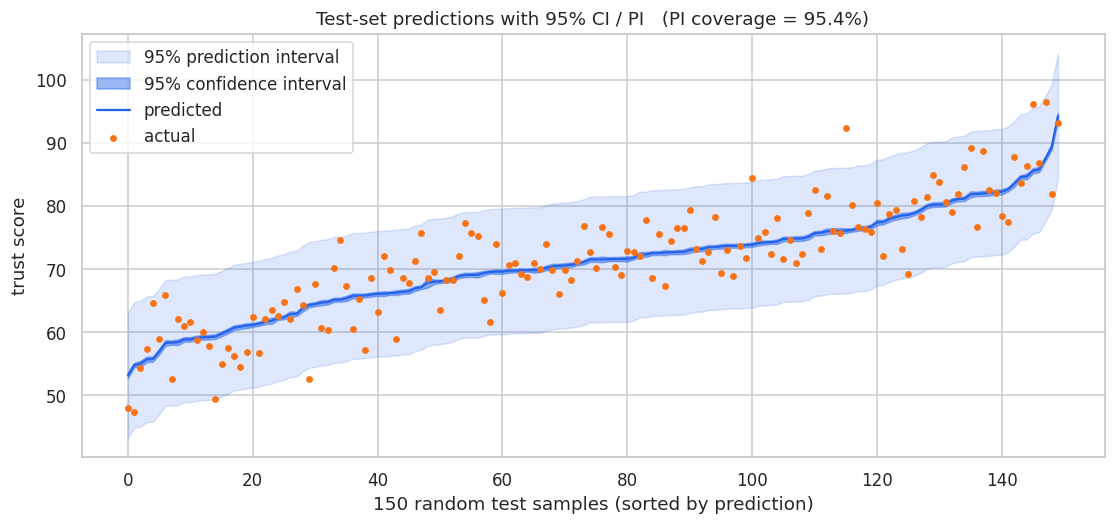

In [20]:
pred = final.get_prediction(X_te_c).summary_frame(alpha=0.05)
cover = np.mean((y_te >= pred.obs_ci_lower) & (y_te <= pred.obs_ci_upper))
print(f"95% PI empirical coverage on test set: {cover*100:.1f}%")
idx = np.random.default_rng(RNG).choice(len(y_te), 150, replace=False)
o = idx[np.argsort(pred["mean"].values[idx])]; x = np.arange(len(o))
fig, ax = plt.subplots(figsize=(12, 5))
ax.fill_between(x, pred.obs_ci_lower.values[o], pred.obs_ci_upper.values[o], color=ACC, alpha=.15, label="95% prediction interval")
ax.fill_between(x, pred.mean_ci_lower.values[o], pred.mean_ci_upper.values[o], color=ACC, alpha=.45, label="95% confidence interval")
ax.plot(x, pred["mean"].values[o], color=ACC, lw=1.5, label="predicted")
ax.scatter(x, y_te[o], s=12, color=ACC2, zorder=3, label="actual")
ax.set_xlabel("150 random test samples (sorted by prediction)"); ax.set_ylabel("trust score")
ax.set_title(f"Test-set predictions with 95% CI / PI   (PI coverage = {cover*100:.1f}%)"); ax.legend(loc="upper left")
save("08_pred_interval_test")

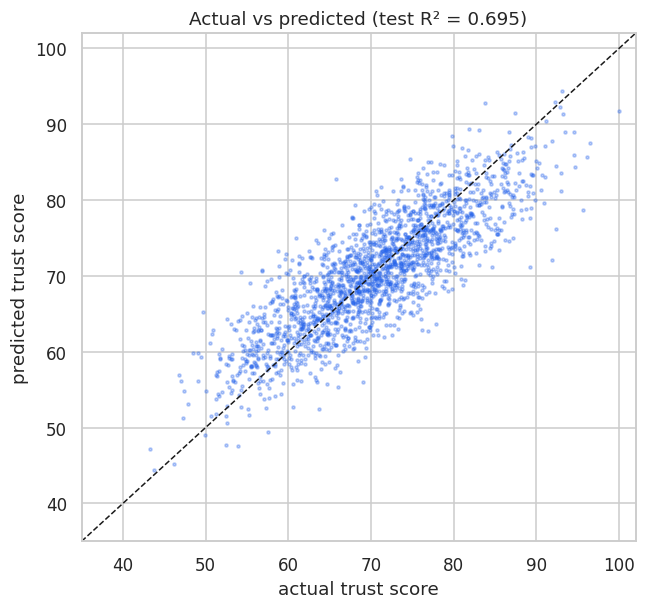

In [21]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(y_te, yhat_te, s=4, alpha=.3, color=ACC)
lim = [35, 102]; ax.plot(lim, lim, "k--", lw=1); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("actual trust score"); ax.set_ylabel("predicted trust score")
ax.set_title(f"Actual vs predicted (test R² = {r2_score(y_te, yhat_te):.3f})")
save("09_actual_vs_pred")

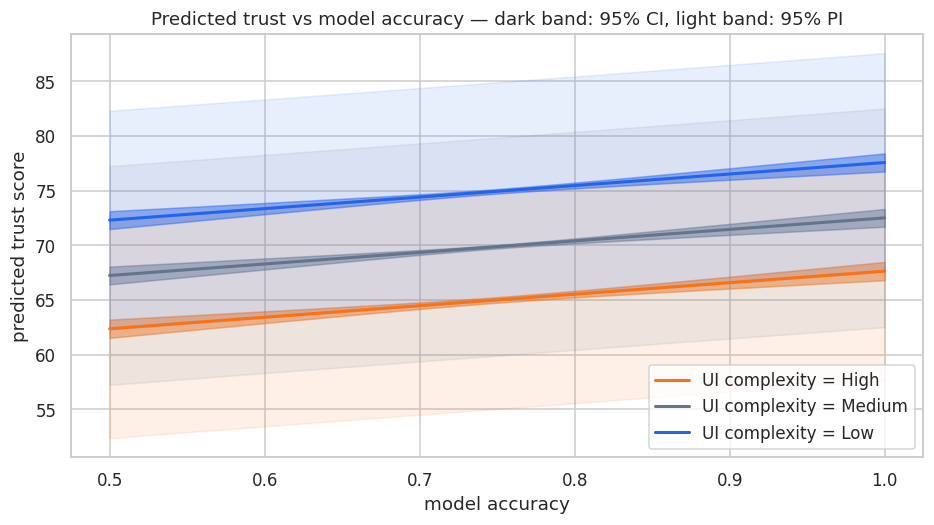

In [22]:
# Effect plot: trust vs model accuracy for the three UI-complexity levels, other features at median / mode
base = pd.DataFrame([{c: (X_tr[c].median() if c in NUM else 0.0) for c in sel_cols}])
for c in CAT:   # categorical groups other than ui_complexity: set to the training mode
    if c in selected and c != "ui_complexity":
        mode = tr[c].mode()[0]
        if f"{c}_{mode}" in base: base[f"{c}_{mode}"] = 1.0
grid = np.linspace(0.5, 1.0, 50)
fig, ax = plt.subplots(figsize=(10, 5))
for lv, col in [("High", ACC2), ("Medium", GREY), ("Low", ACC)]:
    G = pd.concat([base]*len(grid), ignore_index=True)
    G["model_accuracy"] = grid
    if "error_rate" in G: G["error_rate"] = X_tr["error_rate"].median()
    for k in [c for c in sel_cols if c.startswith("ui_complexity_")]: G[k] = 1.0 if k == f"ui_complexity_{lv}" else 0.0
    sf = final.get_prediction(sm.add_constant(G, has_constant="add")).summary_frame(alpha=.05)
    ax.fill_between(grid, sf.obs_ci_lower, sf.obs_ci_upper, color=col, alpha=.10)
    ax.fill_between(grid, sf.mean_ci_lower, sf.mean_ci_upper, color=col, alpha=.45)
    ax.plot(grid, sf["mean"], color=col, lw=2, label=f"UI complexity = {lv}")
ax.set_xlabel("model accuracy"); ax.set_ylabel("predicted trust score")
ax.set_title("Predicted trust vs model accuracy — dark band: 95% CI, light band: 95% PI"); ax.legend()
save("10_effect_accuracy_ui")

### 5.2 評估結論
- 多元線性回歸相較單一特徵的簡單回歸，R² 大幅提升；信任主要由 **信任歷史、模型準確率、介面複雜度、偏誤程度、回饋品質、認知負荷** 決定。
- 人口統計（年齡、教育、文化）、領域、任務風險、時間壓力等特徵對信任幾乎沒有解釋力，Stepwise／Lasso／RFE 三種方法一致將其排除 → 精簡模型表現與全模型相同。
- `error_rate` 與 `model_accuracy` 高度相關（共線性），兩者擇一即可，Stepwise 會自動處理。
- 殘差近似常態、變異大致一致，線性回歸假設成立；95% PI 覆蓋率接近 95%。
- **限制**：這是合成（synthetic）資料，目標分數上限 100 被截斷；真實世界的信任還受到時間與經驗動態影響。

## 6. Deployment（部署）

In [23]:
cols = ["const"] + sel_cols
sel_num = [c for c in selected if c in NUM]
sel_cat = [c for c in selected if c in CAT]
export = {
    "columns": cols, "coef": final.params[cols].tolist(),
    "cov": final.cov_params().loc[cols, cols].values.tolist(),
    "sigma2": float(final.scale), "df_resid": float(final.df_resid),
    "t975": float(stats.t.ppf(0.975, final.df_resid)),
    "numeric": [{"name": c, "min": float(tr[c].min()), "max": float(tr[c].max()), "default": float(tr[c].median()),
                 "step": 1.0 if (tr[c] % 1 == 0).all() else 0.01} for c in sel_num],
    "categorical": [{"name": c, "levels": LEVELS[c], "default": tr[c].mode()[0]} for c in sel_cat],
    "metrics": {k: {m: round(float(v), 4) for m, v in d.items()} for k, d in res.T.to_dict().items()},
    "pi_coverage": float(cover), "n_train": int(len(y_tr)), "n_test": int(len(y_te)), "n_raw": int(len(raw)),
    "selected_groups": selected, "dropped_groups": remaining,
}
with open("docs/trust/model.js", "w", encoding="utf-8") as f:
    f.write("window.MODEL_TRUST = " + json.dumps(export, ensure_ascii=False) + ";")
res.round(4).to_csv(f"{FIG}/model_comparison.csv"); hist.round(4).to_csv(f"{FIG}/stepwise_history.csv", index=False)
coef.round(5).to_csv(f"{FIG}/final_coefficients.csv")
print("exported", len(cols), "coefficients;", "inputs:", sel_num + sel_cat)

exported 11 coefficients; inputs: ['trust_history', 'bias_level', 'feedback_quality', 'model_accuracy', 'cognitive_load', 'error_rate', 'override_frequency', 'regulatory_strictness', 'ui_complexity']


- 模型匯出為 `docs/trust/model.js`，網頁以下拉選單切換到此資料集後，估價器會自動改成「信任分數預測器」，只顯示最終模型用到的特徵。
- 預測：ŷ = xᵀβ；95% PI：ŷ ± t₀.₉₇₅·√(σ² + xᵀCov(β)x)。